# Candidate Datasets:
- SQuAD - ~100,000
- Natural Questions - ~307,000
- TriviaQA - ~100,000

1. collect all the q-a pairs (need also paragraphs if exist)
2. filter out answers (and questions) that appear less than 3 times (with numbers i can just choose close numbers as a cluster instead to make more candidates, same with dates)
3. check for similarity in the question clusters - filter out as little as possible to make the group not closely related (create a graph and Find a Minimum Vertex Cover or Iteratively Prune)
4. now that we have the candidates - show some statistics and potential for dataset size...
5. choose initial question and start build the reasoning chains
6. create alternative answers for each chain (remember to deal with memory and cheatability artifacts)
7. create paragraphs (several styles, fixes size range, etc..)

In [1]:
# Load data from memory:

import json
def load_json(file_path):
    with open(file_path, "r", encoding="utf-8") as file:
        return json.load(file)  # Parse JSON and return as a dictionary

# Example usage
data = load_json("triviaqa_train.json")

FileNotFoundError: [Errno 2] No such file or directory: 'triviaqa_train.json'

In [66]:
answers = set()
for sample in data:
    answers.add(sample['Answer'])

In [67]:
answer_count = {}
for ans in answers:
    answer_count[ans] = 0

for sample in data:
    answer_count[sample['Answer']] += 1

In [68]:
answer_count

{'Larch': 3,
 'Daniel': 3,
 'Grand Canyon': 1,
 'Gospel': 1,
 'First Blood': 1,
 'Chris Barber': 1,
 'Benoxaprofen': 1,
 'Shark (disambiguation)': 2,
 'Zigo': 1,
 'Talaria': 2,
 'Atmosphere of Jupiter': 1,
 'Roundhead': 2,
 'Brogue': 1,
 'United': 2,
 'Gower Peninsula': 5,
 'Seals': 1,
 'Fjord': 1,
 'Valentino Rossi': 2,
 'Mirador': 1,
 '40 Winks': 1,
 'Aida (disambiguation)': 2,
 'Tenzing-Hillary Airport': 1,
 'Trousers': 1,
 'Coatbridge': 1,
 'Three Blind Mice': 3,
 'Mont Blanc': 6,
 'Incubator': 1,
 'Ash': 9,
 'A. montana': 4,
 'Shelley': 2,
 'Uttoxeter': 3,
 'Fierce Creatures': 1,
 'Differential': 1,
 'Reflection': 1,
 'John Curry': 1,
 'Tabasco': 1,
 'Lingua franca (disambiguation)': 2,
 'Hurleston': 1,
 'Sound of the Underground': 1,
 'Alan Jay Lerner': 1,
 'Skeletor': 1,
 'Patagonian Desert': 1,
 'L.A. Law': 3,
 'Markus Zusak': 1,
 'Skirt': 3,
 'Gary Larson': 2,
 'Christopher Reeve': 2,
 'Herbie Hewett': 1,
 'Cockburn Town': 1,
 'Stacia': 1,
 'John Flamsteed': 1,
 'Ready Brek': 

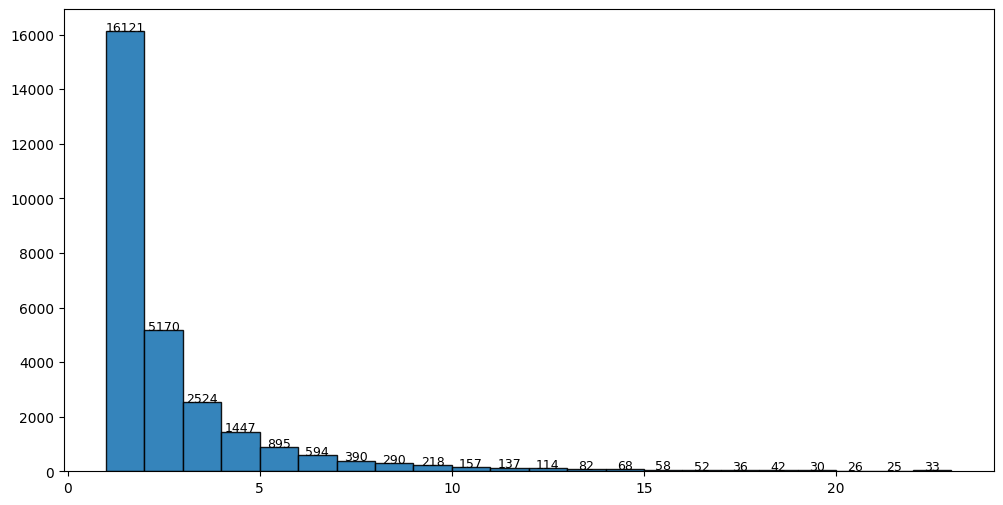

In [69]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(12,6))
counts, bins, patches = ax.hist(answer_count.values(), bins=range(1,24), edgecolor="black", alpha=0.9)
# Annotate each bar with its count
for count, bin_edge in zip(counts, bins[:-1]):  # Exclude the last bin edge
    ax.text(bin_edge + 0.5, count + 0.5, str(int(count)), ha="center", fontsize=9)
plt.show()

In [74]:
print(sum(counts[1:]))
print(sum(counts[2:]))

12388.0
7218.0


In [4]:
new_dataset = {}
for ans in answers:
    new_dataset[ans] = []

for sample in data:
    new_dataset[sample['Answer']].append(sample['Question'])

In [5]:
filtered_dataset = {}

for key, value in new_dataset.items():
    if len(value) >= 3:
        filtered_dataset[key] = value

In [9]:
from random import choice

random_answer = choice(list(filtered_dataset.keys()))

print(f'Answer: {random_answer}')
print('Questions:')
for question in filtered_dataset[random_answer]:
    print(f'- {question}')

Answer: Baron Carrington
Questions:
- Who is the only member of Winston Churchill’s Government (a Parliamentary Secretary of Agriculture) who is still alive (95 years)?
- Who was the UK Foreign Secretary from 1979 to 1982, resigning following the Argentinean invasion of the Falklands?
- Born in 1919, he has been First Lord of the Admiralty, Secretary of State for Energy, Defence Secretary, Foreign Secretary, Secretary General of NATO and is now Father of the House of Lords. Who is he?
- Who was the British foreign secretary who resigned during the battle of the Falklands


In [2]:
squad_dataset = load_json("C:/Users/danie/Desktop/train-v2.0.json")

In [63]:
import spacy
import wikipedia

# Load spaCy's Named Entity Recognizer
nlp = spacy.load("en_core_web_sm")

def get_wikipedia_entity(answer):
    """Check if the answer is a valid Wikipedia entity."""
    try:
        page = wikipedia.page(answer)
        return page.title  # Return canonical Wikipedia entity
    except:
        try:
            page = wikipedia.page(answer, auto_suggest=False)
            return page.title
        except:
            return None  # Not a Wikipedia entity

def is_wikipedia_entity(answer):
    """Determine if an answer is a Wikipedia entity using NER and Wikipedia API."""
    doc = nlp(answer)
    for ent in doc.ents:
        if ent.label_ in {"PERSON", "ORG", "GPE", "NORP", "EVENT"}:
            entity = get_wikipedia_entity(answer)
            if entity:
                return entity  # Valid Wikipedia entity
    return None  # Not an entity

In [18]:
import re

def is_number(answer):
    """Check if the answer is a number (integer, decimal, fraction)."""
    return bool(re.match(r"^\d+(\.\d+)?$", answer))

def is_numeric_entity(answer):
    """Check for numbers using spaCy NER."""
    doc = nlp(answer)
    return any(ent.label_ in {"CARDINAL", "QUANTITY", "PERCENT", "MONEY"} for ent in doc.ents)

In [17]:
from dateutil.parser import parse

def is_date(answer):
    """Check if the answer is a date using regex and parsing."""
    try:
        parse(answer, fuzzy=False)
        return True
    except:
        return False

def is_date_entity(answer):
    """Check for dates using spaCy NER."""
    doc = nlp(answer)
    return any(ent.label_ == "DATE" for ent in doc.ents)

In [16]:
def classify_answer(answer):
    """Classify an answer into Wikipedia Entity, Number, Date, or Free-form text."""
    entity = is_wikipedia_entity(answer)
    if entity:
        return "Wikipedia Entity", entity
    if is_number(answer) or is_numeric_entity(answer):
        return "Number", answer
    if is_date(answer) or is_date_entity(answer):
        return "Date", answer
    return "Free-form", answer  # Default case

In [9]:
from tqdm import tqdm

answers = []

for sample in squad_dataset['data'][:8]:
    for samp in sample['paragraphs'][:8]:
        for sam in samp['qas'][:5]:
            try:
                answers.append(sam['answers'][0]['text'])
            except:
                pass

distribution = {'Date': 0, 'Number': 0, 'Wikipedia Entity': 0, 'Free-form': 0}

print(len(answers))

squad_entities = []
squad_numbers = []
squad_dates = []

for ans in tqdm(answers):
    category, extracted = classify_answer(ans)
    distribution[category] += 1
    if category == 'Wikipedia Entity':
        squad_entities.append(extracted)
    if category == 'Number':
        squad_numbers.append(extracted)
    if category == 'Date':
        squad_dates.append(extracted)

print(distribution)

304


  1%|█                                                                                 | 4/304 [00:00<00:43,  6.88it/s]C:\Users\danie\Desktop\Thesis_Experiment\Thesis_repo\Multi-Hop-Knowledge-Conflicts\dev_env\lib\site-packages\wikipedia\wikipedia.py:389: GuessedAtParserWarning: No parser was explicitly specified, so I'm using the best available HTML parser for this system ("html.parser"). This usually isn't a problem, but if you run this code on another system, or in a different virtual environment, it may use a different parser and behave differently.

The code that caused this warning is on line 389 of the file C:\Users\danie\Desktop\Thesis_Experiment\Thesis_repo\Multi-Hop-Knowledge-Conflicts\dev_env\lib\site-packages\wikipedia\wikipedia.py. To get rid of this warning, pass the additional argument 'features="html.parser"' to the BeautifulSoup constructor.

  lis = BeautifulSoup(html).find_all('li')
100%|████████████████████████████████████████████████████████████████████████████████

{'Date': 20, 'Number': 69, 'Wikipedia Entity': 83, 'Free-form': 132}


In [12]:
num_shared = 0
num_total = len(squad_entities)

for ans in squad_entities:
    if ans in answers:
        num_shared += 1

print(f'{num_shared} / {num_total}')

22 / 83


In [15]:
squad_entities

['Houston',
 'Forbes',
 'Forbes',
 'African Americans',
 'Xenon',
 'Boston',
 'Mathew Knowles',
 'Marc Nelson (entertainer)',
 'Book of Isaiah',
 'French polish',
 'Mallorca',
 'Sketch (music)',
 'Salon (Paris)',
 'France',
 'Frédéric Chopin',
 'Frédéric Chopin',
 'Police',
 'Nicholas',
 'Lorraine',
 'Bengaluru Palace',
 'Wojciech Żywny',
 'Mainland Chinese',
 '5th Karmapa, Deshin Shekpa',
 'Karma Kagyu',
 'Yarlung dynasty',
 'Ögedei Khan',
 'Ögedei Khan',
 'Töregene Khatun',
 'Khagan',
 'Ögedei Khan',
 '2nd Karmapa, Karma Pakshi',
 'Apply',
 'List of Oppo products',
 'IPod Shuffle',
 'ITunes',
 'Microsoft PowerPoint',
 'ITunes',
 'Dieter Rams',
 'Chicago',
 'Helvetica',
 'Nintendo',
 'Universe of The Legend of Zelda',
 'Midna',
 'Midna',
 'Nintendo Selects',
 'The Legend of Zelda: Ocarina of Time',
 'Lord',
 'Nunchaku',
 'Well',
 'Midna',
 'Daniel Craig',
 'James (band)',
 'Miss Moneypenny',
 'Spectre (2015 film)',
 'Royal Albert Hall Organ',
 'Home',
 'Ernst Stavro Blofeld',
 'Ernst 

### Natural Questions:

In [32]:
import mmap
import json
from tqdm import tqdm

nq_dataset = []

file_path = "C:/Users/danie/Downloads/v1.0-simplified_simplified-nq-train.jsonl/simplified-nq-train.jsonl"

with open(file_path, "r") as f:
    mmapped_file = mmap.mmap(f.fileno(), 0, access=mmap.ACCESS_READ)
    i = 0
    for line in tqdm(iter(mmapped_file.readline, b"")):
        i += 1
        data = json.loads(line.decode("utf-8").strip())  # Decode each line
        if len(data['annotations'][0]['short_answers']) > 0:
            start = data['annotations'][0]['short_answers'][0]['start_token']
            end = data['annotations'][0]['short_answers'][0]['end_token']
            nq_dataset.append({'Question': data['question_text'], 'Answer': ' '.join(data['document_text'].split()[start:end])})

186505it [01:42, 1811.83it/s]


KeyboardInterrupt: 

In [33]:
len(nq_dataset)

65010

In [10]:
import mmap
import json
from tqdm import tqdm

file_path = "C:/Users/danie/Downloads/v1.0-simplified_simplified-nq-train.jsonl/simplified-nq-train.jsonl"
output_path = "processed_nq.jsonl"  # Save processed data

# Count total lines for tqdm
with open(file_path, "r", encoding="utf-8") as f:
    total_lines = sum(1 for _ in f)

# Process line by line and write directly to a file
with open(file_path, "r") as f, open(output_path, "w", encoding="utf-8") as out_file:
    mmapped_file = mmap.mmap(f.fileno(), 0, access=mmap.ACCESS_READ)
    
    for line in tqdm(iter(mmapped_file.readline, b""), total=total_lines, desc="Processing"):
        try:
            data = json.loads(line.decode("utf-8").strip())  # Decode each line
            
            # Extract short answer if available
            if data["annotations"] and data["annotations"][0]["short_answers"]:
                start = data["annotations"][0]["short_answers"][0]["start_token"]
                end = data["annotations"][0]["short_answers"][0]["end_token"]
                answer_text = " ".join(data["document_text"].split()[start:end])
                
                # Write result to file (one JSON per line)
                json.dump({"Question": data["question_text"], "Answer": answer_text}, out_file)
                out_file.write("\n")  # Newline for JSONL format

        except json.JSONDecodeError as e:
            print(f"Skipping bad JSON line: {e}")

        # Manually free memory after processing each line
        del data 

Processing: 100%|████████████████████████████████████████████████████████████| 307373/307373 [03:22<00:00, 1517.13it/s]


In [14]:
import json
with open("processed_nq.jsonl") as f:
    nq_dataset = [json.loads(line) for line in f]

In [15]:
nq_dataset

[{'Question': 'which is the most common use of opt-in e-mail marketing',
  'Answer': "a newsletter sent to an advertising firm 's customers"},
 {'Question': 'how i.met your mother who is the mother',
  'Answer': 'Tracy McConnell'},
 {'Question': 'who had the most wins in the nfl', 'Answer': 'Tom Brady'},
 {'Question': 'who played mantis guardians of the galaxy 2',
  'Answer': 'Pom Klementieff'},
 {'Question': 'the nashville sound brought a polished and cosmopolitan sound to country music by',
  'Answer': 'the use of lush string arrangements with a real orchestra and often , background vocals provided by a choir'},
 {'Question': 'what channel is the premier league on in france',
  'Answer': 'SFR Sport'},
 {'Question': 'who needs to be in the car with a permit driver',
  'Answer': 'an adult licensed driver who is at least 21 years of age or older and in the passenger seat of the vehicle at all times'},
 {'Question': "god's not dead a light in the darkness release date",
  'Answer': 'Marc

In [64]:
distribution = {'Date': 0, 'Number': 0, 'Wikipedia Entity': 0, 'Free-form': 0}
nq_entities = []
nq_numbers = []
nq_dates = []

for sample in tqdm(nq_dataset[:100]):
    category, extracted = classify_answer(sample['Answer'])
    distribution[category] += 1
    if category == 'Wikipedia Entity':
        print(f"Question: {sample['Question']} --> {sample['Answer']} --> {category}: {extracted}")
        nq_entities.append(extracted)
    elif category == 'Number':
        print(f"Question: {sample['Question']} --> {sample['Answer']} --> {category}: {extracted}")
        nq_numbers.append(extracted)
    elif category == 'Date':
        print(f"Question: {sample['Question']} --> {sample['Answer']} --> {category}: {extracted}")
        nq_dates.append(extracted)
    else:
        print(f"Question: {sample['Question']} --> {sample['Answer']} --> {category}: {extracted}")

print(distribution)

  0%|                                                                                          | 0/100 [00:00<?, ?it/s]

Question: which is the most common use of opt-in e-mail marketing --> a newsletter sent to an advertising firm 's customers --> Free-form: a newsletter sent to an advertising firm 's customers


  2%|█▋                                                                                | 2/100 [00:00<00:25,  3.92it/s]

Question: how i.met your mother who is the mother --> Tracy McConnell --> Wikipedia Entity: The Mother (How I Met Your Mother)


  3%|██▍                                                                               | 3/100 [00:01<00:58,  1.65it/s]

...

Question: what film has the song don't you forget about me --> The Breakfast Club --> Wikipedia Entity: The Breakfast Club
Question: what is the lowest temperature ever recorded in vermont --> − 50 ° F / − 46 ° C --> Free-form: − 50 ° F / − 46 ° C
Question: when was the last time mount saint helens exploded --> May 18 , 1980 --> Date: May 18 , 1980
Question: how many 7 elevens are in the world --> 66,579 --> Number: 66,579
Question: when do booth and brennan become a couple --> At the start of Season 7 --> Date: At the start of Season 7


 99%|████████████████████████████████████████████████████████████████████████████████▏| 99/100 [00:34<00:00,  3.83it/s]

Question: who sang nice one cyril nice one son --> Cockerel Chorus --> Wikipedia Entity: Nice One Cyril


100%|████████████████████████████████████████████████████████████████████████████████| 100/100 [00:35<00:00,  2.82it/s]

Question: who sang red red wine in the 80's --> Neil Diamond --> Wikipedia Entity: Neil Diamond
{'Date': 14, 'Number': 20, 'Wikipedia Entity': 32, 'Free-form': 34}


In [65]:
nq_entities

['The Mother (How I Met Your Mother)',
 'Tom Brady',
 'Pom Klementieff',
 'Miroslav Lajčák',
 'Kareem Abdul-Jabbar',
 '2020 Summer Olympics',
 'Kida Burns',
 'Freddie Highmore',
 'Adam Sandler',
 'Manchester United F.C.',
 'Neil Armstrong',
 'The Lego Movie',
 'Rajyavardhan Singh Rathore',
 'Seattle',
 'Black Dirt Region',
 'Gary Oldman',
 'Alejandro García Padilla',
 'Ellen Burstyn',
 'Dublin',
 'Tina Cole',
 'Kansas',
 'Michael Jackson',
 'Natalie Morales (actress)',
 'Justin Timberlake',
 'Franklin D. Roosevelt',
 'Uzo Aduba',
 'Tommy Mottola',
 'David (Michelangelo)',
 'Ha Hyun-woo',
 'The Breakfast Club',
 'Nice One Cyril',
 'Neil Diamond']

In [23]:
nq_entities

['The Mother (How I Met Your Mother)',
 'Pom Klementieff',
 'Miroslav Lajčák',
 'Kareem Abdul-Jabbar',
 '2020 Summer Olympics',
 'Kida Burns',
 'Freddie Highmore',
 'Manchester United F.C.',
 'Neil Armstrong',
 'Rajyavardhan Singh Rathore',
 'Seattle',
 'Black Dirt Region',
 'Alejandro García Padilla',
 'Dublin',
 'Tina Cole',
 'Kansas',
 'Natalie Morales (actress)',
 'Justin Timberlake',
 'Franklin D. Roosevelt',
 'Uzo Aduba',
 'Tommy Mottola',
 'David (Michelangelo)',
 'Ha Hyun-woo',
 'The Breakfast Club',
 'Nice One Cyril',
 'Neil Diamond']